# Homework 6: Linear Regression Modleing and Diagnostics
Build a predictive model for life expectancy using scikit-learn and perform a diagnostic audit to ensure the model’s coefficients are stable and mathematically sound.

## Task 1: Baseline Modeling
Load the WHO Life Expectancy Dataset, remove non-numeric columns (Country, Year), Convert Status column to  numeric, handle missing values.
- Use StandardScaler from sklearn.preprocessing to scale all independent variables. ("Life expectancy" is dependent variable)
- Train a LinearRegression model using the scaled features.
- Report the R-Squared Score.
- Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.

## Task 2: Iterative Diagnostic (VIF < 5)
Before analyzing the data, you must understand the Variance Inflation Factor (VIF) diagnostic. VIF measures multicollinearity, the degree to which your predictors are redundant.
High multicollinearity inflates the variance of coefficients, making them unreliable and difficult to interpret.
VIF is calculated by regressing one predictor against all others, then you obtain R_Squared and then compute VIF = 1/(1-R_Squared)
You sohuld use a cutoff of 5. Any variable with a VIF > 5 is considered too redundant and will be removed to improve the model's structural integrity. To do that follow the instruction below:

### Write a loop to iteratively remove the most redundant feature:
    1. Calculate VIF for every feature in the scaled dataset.
    2. Find the variable with the highest VIF.
    3. If VIF > 5, remove that feature from the data.
    4. Repeats the process until all remaining features have a VIF < 5
    - Note that in each iteration you remove only the highest VIF if it is greatet than 5!
    
## Task 3: Comparison of Model Results
    - Train a new LinearRegression model using only the independent features that survived the VIF diagnostic test.
    - Report the R-Squared Score.
    - Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.
    - Are the top 5 predicotrs remain the same as those of the Baseline Model?

## Task 4: Residual Analysis and Normality
A good regression model should have errors (residuals) that are normally distributed and centered around zero.

    - Generate a histogram of the residuals for your baseline and clean model side by side.
    - Does the error distributions look like a bell curve?

## Task 5: The Interaction Investigation
In the real world application, the effect of one variable often depends on another. This is called an interaction.

    - Select two variables of your choice from the dataset (only variables with VIF < 5) that you believe might have a combined effect (e.g., Alcohol and GDP, or BMI and HIV/AIDS,). Write one sentence explaining why you think they interact.
    - Create a new column in your dataframe by multiplying these two variables together.
    - Train a new model by adding this new interaction term to your dataset and fit it again using LinearRegression.
    - Report the R-Squared Score.
    - Is the interaction coeficient positive or negative? Has adding it improved the Model performance?




## Setup and Dataset
I used the WHO Life Expectancy dataset to examine which variables were associated with life expectancy. The code below loads the data and the libraries used in the analysis.

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

In [ ]:
dataset_path = "/content/Life Expectancy Data.csv"
df = pd.read_csv(dataset_path)
df.head(5)
df.shape

(2938, 22)

## Task 1: Baseline Modeling
I removed Country and Year, converted Status to 0 for developing countries and 1 for developed countries, and filled missing numeric values with their column means. I then scaled the predictors and trained a linear regression model. Scaling lets me compare coefficient sizes using the same units: a one-standard-deviation change in each predictor.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Clean column names (strip trailing spaces)
df.columns = df.columns.str.strip()

# 2. Drop Country and Year columns
df_baseline = df.drop(columns=['Country', 'Year'])

# 3. Convert Status to numeric (Developing = 0, Developed = 1)
df_baseline['Status'] = df_baseline['Status'].map({'Developing': 0, 'Developed': 1})

# 4. Handle missing values (impute with column mean)
df_baseline = df_baseline.apply(lambda x: x.fillna(x.mean()))

# 5. Separate independent and dependent variables
X = df_baseline.drop(columns=['Life expectancy'])
y = df_baseline['Life expectancy']

# 6. Scale the independent variables
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)

# 7. Train Linear Regression
model = LinearRegression()
model.fit(X_scaled, y)
r2_score = model.score(X_scaled, y)

print(f"Baseline R-Squared Score: {r2_score:.4f}\n")

# 8. Coefficient Analysis
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_,
    'Absolute_Coefficient': np.abs(model.coef_)
}).sort_values(by='Absolute_Coefficient', ascending=False)

print("Features ranked by absolute coefficient values:")
print(coefficients.to_string(index=False))

Baseline R-Squared Score: 0.8197

Features ranked by absolute coefficient values:
                        Feature  Coefficient  Absolute_Coefficient
              under-five deaths   -11.999690             11.999690
                  infant deaths    11.779303             11.779303
                Adult Mortality    -2.465513              2.465513
                       HIV/AIDS    -2.384912              2.384912
                      Schooling     2.139349              2.139349
Income composition of resources     1.172785              1.172785
                     Diphtheria     0.948453              0.948453
                            BMI     0.884379              0.884379
                          Polio     0.667832              0.667832
                         Status     0.606982              0.606982
                            GDP     0.431240              0.431240
           thinness  1-19 years    -0.361598              0.361598
                    Hepatitis B    -0.333197   

### Baseline Results
The baseline model had an R² of **0.8197**, meaning it explained about **81.97%** of the variation in life expectancy in the data used to fit it. The five largest absolute coefficients were under-five deaths, infant deaths, Adult Mortality, HIV/AIDS, and Schooling. However, a large coefficient does not automatically mean a variable is the most important overall, especially if some predictors overlap with each other.

These are training results, so they do not tell me how well the model would predict new data. The mean-filling step also included missing life expectancy values, which is a limitation because those filled values are not actual observed outcomes.

## Task 2: Iterative VIF Diagnostic
VIF checks how much a predictor overlaps with the other predictors. I used a loop to remove only the variable with the highest VIF above 5, then recalculated the VIF values. I repeated this until no remaining variable exceeded the cutoff.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vifs(df_features):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = df_features.columns
    vif_data["VIF"] = [variance_inflation_factor(df_features.values, i) for i in range(df_features.shape[1])]
    return vif_data

# Initialize with scaled features
X_vif_clean = X_scaled.copy()

print("Starting iterative VIF removal...")
while True:
    vif_df = calculate_vifs(X_vif_clean)
    max_vif_row = vif_df.loc[vif_df['VIF'].idxmax()]
    max_val = max_vif_row['VIF']
    max_feat = max_vif_row['Feature']

    if max_val > 5:
        print(f"Removing '{max_feat}' with VIF = {max_val:.2f}")
        X_vif_clean = X_vif_clean.drop(columns=[max_feat])
    else:
        break

print("\nAll remaining features have VIF < 5:")
final_vifs = calculate_vifs(X_vif_clean).sort_values(by='VIF', ascending=False)
print(final_vifs.to_string(index=False))

Starting iterative VIF removal...
Removing 'infant deaths' with VIF = 176.65
Removing 'thinness 5-9 years' with VIF = 8.83
Removing 'GDP' with VIF = 5.18

All remaining features have VIF < 5:
                        Feature      VIF
                      Schooling 3.319010
Income composition of resources 2.966889
                     Diphtheria 2.179435
              under-five deaths 2.165243
           thinness  1-19 years 1.972329
                          Polio 1.936966
                         Status 1.863949
                        Alcohol 1.800069
                Adult Mortality 1.729807
                            BMI 1.697119
                     Population 1.438266
                       HIV/AIDS 1.414930
                    Hepatitis B 1.388923
                        Measles 1.373648
         percentage expenditure 1.346382
              Total expenditure 1.176337


### VIF Results
The loop removed **infant deaths**, **thinness 5-9 years**, and **GDP**, in that order. Infant deaths had a particularly high VIF of about **176.65**, showing a lot of overlap with the other predictors. After those removals, all remaining VIF values were below 5, with Schooling having the highest at about **3.32**.

## Task 3: Comparison of Model Results
I trained another linear regression model using the predictors that remained after the VIF check. I compared its R² and five largest absolute coefficients with the baseline model.

In [ ]:
# 1. Train a new Linear Regression model using only VIF-cleared features
clean_model = LinearRegression()
clean_model.fit(X_vif_clean, y)
clean_r2_score = clean_model.score(X_vif_clean, y)

print(f"Clean Model R-Squared Score: {clean_r2_score:.4f}\n")

# 2. Coefficient Analysis for the Clean Model
clean_coefficients = pd.DataFrame({
    'Feature': X_vif_clean.columns,
    'Coefficient': clean_model.coef_,
    'Absolute_Coefficient': np.abs(clean_model.coef_)
}).sort_values(by='Absolute_Coefficient', ascending=False)

print("Clean Model Features ranked by absolute coefficient values:")
print(clean_coefficients.to_string(index=False))

# 3. Check if the top 5 predictors remain the same
baseline_top5 = set(coefficients.head(5)['Feature'])
clean_top5 = set(clean_coefficients.head(5)['Feature'])

print(f"\nBaseline Top 5 Predictors: {baseline_top5}")
print(f"Clean Model Top 5 Predictors: {clean_top5}")
if baseline_top5 == clean_top5:
    print("\nYes, the top 5 predictors remain exactly the same!")
else:
    print("\nNo, the top 5 predictors have changed because multicollinear features were removed.")

Clean Model R-Squared Score: 0.8107

Clean Model Features ranked by absolute coefficient values:
                        Feature  Coefficient  Absolute_Coefficient
                Adult Mortality    -2.524275              2.524275
                       HIV/AIDS    -2.448942              2.448942
                      Schooling     2.193850              2.193850
Income composition of resources     1.348040              1.348040
                     Diphtheria     1.106669              1.106669
                            BMI     0.912956              0.912956
                          Polio     0.747171              0.747171
                         Status     0.606838              0.606838
         percentage expenditure     0.503612              0.503612
                    Hepatitis B    -0.391876              0.391876
              under-five deaths    -0.322669              0.322669
                        Measles    -0.266898              0.266898
           thinness  1-19 years 

### Model Comparison
The model after VIF removal had an R² of **0.8107**, compared with **0.8197** for the baseline model. It explained slightly less variation in the training data, but the remaining predictors had less overlap.

The top five predictors did not stay the same:

| Rank by absolute coefficient | Baseline model | Model after VIF removal |
|---|---|---|
| 1 | under-five deaths | Adult Mortality |
| 2 | infant deaths | HIV/AIDS |
| 3 | Adult Mortality | Schooling |
| 4 | HIV/AIDS | Income composition of resources |
| 5 | Schooling | Diphtheria |

Adult Mortality, HIV/AIDS, and Schooling stayed in the top five. Income composition of resources and Diphtheria replaced the two childhood death measures in the ranking. Under-five deaths was still included in the model, but its coefficient became much smaller.

## Task 4: Residual Analysis and Normality
I calculated residuals by subtracting the predicted life expectancy from the actual value used in the model. I then plotted both models' residuals side by side to check their shape and whether they were centered near zero.

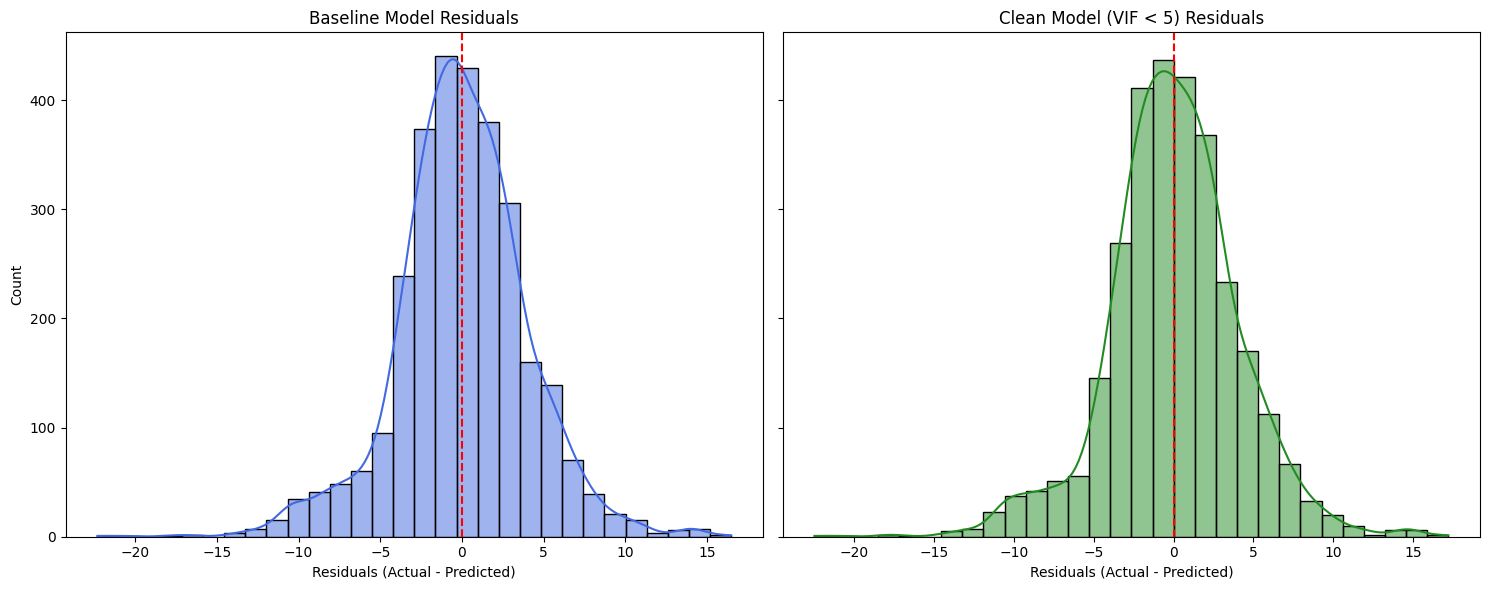

In [ ]:
# Calculate residuals
residuals_baseline = y - model.predict(X_scaled)
residuals_clean = y - clean_model.predict(X_vif_clean)

# Plot residuals side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

sns.histplot(residuals_baseline, kde=True, color='royalblue', ax=axes[0], bins=30)
axes[0].set_title("Baseline Model Residuals")
axes[0].set_xlabel("Residuals (Actual - Predicted)")
axes[0].set_ylabel("Count")
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)

sns.histplot(residuals_clean, kde=True, color='forestgreen', ax=axes[1], bins=30)
axes[1].set_title("Clean Model (VIF < 5) Residuals")
axes[1].set_xlabel("Residuals (Actual - Predicted)")
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)

plt.tight_layout()
plt.show()

### Residual Interpretation
Both histograms look roughly like bell curves and are centered near zero. However, neither is perfectly symmetric, and both have some large errors in the tails. The shapes look similar after removing the high-VIF variables, so the plots suggest approximate normality rather than proving it.

## Task 5: The Interaction Investigation
I chose **Schooling** and **Income composition of resources** because I think the relationship between schooling and life expectancy could depend on the resources available in a country.

Both variables passed the VIF check before adding the interaction. I multiplied their scaled values to create the interaction term, kept the original predictors, and fit another model.

In [ ]:
# 1. Create a new interaction term
X_interaction = X_vif_clean.copy()
X_interaction['Schooling_x_Income'] = X_interaction['Schooling'] * X_interaction['Income composition of resources']

# 2. Train a new model with the interaction term
interaction_model = LinearRegression()
interaction_model.fit(X_interaction, y)
interaction_r2_score = interaction_model.score(X_interaction, y)

# 3. Retrieve interaction term coefficient
interaction_coef = interaction_model.coef_[X_interaction.columns.get_loc('Schooling_x_Income')]

print(f"Interaction Model R-Squared Score: {interaction_r2_score:.4f}")
print(f"Previous Clean Model R-Squared Score: {clean_r2_score:.4f}")
print(f"Interaction Term ('Schooling_x_Income') Coefficient: {interaction_coef:.4f}\n")

if interaction_r2_score > clean_r2_score:
    print(f"Adding the interaction term increased training R-squared by {interaction_r2_score - clean_r2_score:.4f}.")
else:
    print("Adding the interaction term did not increase training R-squared.")

Interaction Model R-Squared Score: 0.8114
Previous Clean Model R-Squared Score: 0.8107
Interaction Term ('Schooling_x_Income') Coefficient: 0.2099

Adding the interaction term increased training R-squared by 0.0006.


### Interaction Results
The interaction model had an R² of **0.8114**, compared with **0.8107** before adding the term. The interaction coefficient was **positive**, at about **0.2099**. This means the model estimated a more positive relationship between schooling and life expectancy when the resource measure was higher, while holding the other predictors constant.

The increase in training R² was very small, about **0.0006** based on the unrounded scores. Adding a predictor to this type of regression cannot lower training R², so this increase alone does not show that the interaction improves predictions on new data. I would need to check the model on separate data before making that conclusion.